In [1]:
import tensorflow as tf
physical_device = tf.config.experimental.list_physical_devices('GPU')
print(f'Device found : {physical_device}') #can tensorflow see a GPU?
tf.config.experimental.get_memory_growth(physical_device[0]) #Is GPU being used? If not, this returns nothing or False
tf.config.experimental.set_memory_growth(physical_device[0],True) #Make it use GPU

Device found : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [127]:
#Quick note:
#We'll be using tf.keras -- version of keras that comes with tensorflow
#For our purposes, there isn't much of a difference
#tf.keras is hopefully easier to reconcile with online resources if you get to googling.

## A comment on subject design
Before we start, a comment is needed about the design of DTSC301. In general, tutorials and forums are designed so that we can focus on specific ideas. These ideas are new (e.g., what is an ANN) and usually require careful thought. To help you focus on those ideas, the forums and tutorials try to avoid any complexity that isn't related to those ideas. Examples:
* Our first tutorial considered a dataset of only numerical features, and focused almost entirely on less than 10 lines of code used to design, compile, and fit an ANN. 
* In the second week, we held the model-specific code constant, and focused on 1. getting a dataset ready for your model and 2. the thought process of improving your model. 
* A lot of effort has been put into ensuring you don't really have to think about managing your Python environments, whether because you use Colab or because of how our tutorial room has been prepared.
* In tutorial 2, you were given a function that can help you to split your data into train/validate/test. That function is expected to be useful for your assignments, and means you don't need to install new packages. It also means you don't have to write complex Python code yourself, and can instead focus on the neural networks at the core of the subject.

*Why am I telling you this?* You should be aware we are avoiding tangents where possible so that we can better focus on our core content about how ANNs work. As put by Jeremy Howard, he would need to rename his book from [Practical Deep Learning for Coders](https://fastai.github.io/fastbook2e/) to *Everything You Ever Wanted to Know About Ubuntu System Administration, NVIDIA Driver Installation, apt-get, conda, pip, and Jupyter Notebook Configuration* if all of these tangents were pursued. 

*Why am I telling you this **now**?* Many computer vision problems (today: image classification) are associated with "big" data in the sense that the volume of data affects your normal workflow. Specifically, you are unlikely to be able to load the entire dataset into your machine's working memory, especially if using a GPU. We thus need to talk about data input pipelines and the process of massaging your starting files into a folder structure that meshes with these pipelines. Because the process of setting up your data into a suitable folder structure is so integral to tackling these types of problems, this is a complexity that we can't avoid. You should look carefully at the code we use today to go from our starting files to a good folder structure, and you should think about how you might write your own code to account for different starting points. For example, what if your image files were numbered 1 to 10,000, but the label for each image was in an Excel file rather than in the file name?



## Our First Image Classifier


As discussed in class, there are two interesting aspects of our data in computer vision tasks:
* They are 3-dimensional volumes, and we want to use a model that captures the inherent structure (CNNs)
* It is often unrealistic to fit the entire dataset into working memory, and so we must set up Data Generators that read in batches of data as needed by the network.

Let's focus on the latter element, as it's hard to experiment with our models until we have a workflow for our data.




## Our Data

We'll consider a commonly used practice dataset for our first CNN - pictures that are labelled as "cat" or "dog" (binary classification). You can download this dataset from iLearn in either a full version (10,000 pictures) or a small version (5,000 pictures). 

Whichever version you use, it is worth noting a few characteristics of our data
* We don't have enormous datasets relative to the complexity of the problem. 
* Bayes error (minimum achievable error) should be close to zero.

You can download the dataset to anywhere you want, whether your OneDrive or your Google Drive. You must be able to specify the filepath to the location of your data. The downloaded and extracted dataset will be in a pretty raw format - it's just one folder of 10,000 picture files. Each filename is either "dog" or "cat", followed by the image number for that category. 

To begin, we'll create train, validate, and test folders. In each folder, we'll have two subfolders, "dog" and "cat", containing the class-specific images for that split of the data. Once we have this folder structure, we can train a model by pointing it at the train folder, validate it by pointing it at the validate folder, and then evaluate it on test by, you guessed it, pointing it at the test folder. It is worth highlighting that the two subfolders will dictate the label associated with each image.




#### Step 1: Folder Structure

In the below chunks, a function is being created to help us take a single folder filled with images and move some of them into a newly created subfolder (subset_name) with two sub-subfolders ('cat' and 'dog'). This isn't a general purpose function. If your data isn't of the format "label.number.jpg", it won't work. It also expects that your labels are cat or dog. 

Later in the course, you'll be given a set of images with unique but meaningless file names. You'll also be given an Excel file containing a column of filenames and a corresponding column of labels. I encourage you to think about how you might achieve the desired folder structure from that starting point.

In [2]:
import os, shutil, pathlib
import numpy as np

core_path = "C:/Users/13261609/OneDrive - Bond University/AML/261/Week 4/"
unzip_path = core_path + "CatsVsDogsAllImages/CatsVsDogsAllImages/"
data_path = core_path + "CatsVsDogsPrepped/"

In [18]:
def make_subset(subset_name, start_index, end_index):
    for category in ("cat", "dog"):
        data_dir = data_path + subset_name +"/" + category
        os.makedirs(data_dir)              #create a subfolder
        filenames = [f"{category}.{i}.jpg" for i in range(start_index+1, end_index+1)]
        for fname in filenames:
            shutil.copyfile(src = unzip_path + fname,
                            dst = data_dir + "/" + fname)

In [19]:
#let's do a 50/25/25 split
ratios = [.5,.25,.25]
num_imgs = len(os.listdir(unzip_path))/2 #/2 for number in each category
train_end = int(ratios[0]*num_imgs)
val_end = train_end+int(ratios[1]*num_imgs)
test_end = int(num_imgs)


In [20]:
make_subset("train", start_index=0, end_index=train_end)
make_subset("val", start_index=train_end, end_index=val_end)
make_subset("test", start_index=val_end, end_index=test_end-1)

#### Step 2: Dataset objects

We started with a single folder containing all the images. We've converted this to the following folder structure:
* train
    * cat
    * dog
* val
    * cat
    * dog
* test
    * cat
    * dog

Having set up a nice folder structure, we can now create the objects that Keras will use to load images when it needs to. To do this, we'll use a utility function from `tf.keras` to create a `tf.data.Dataset` object. 

In [21]:
from tensorflow.keras.utils import image_dataset_from_directory

This utility function will let us specify a directory containing images and load in images in batches. Because our network requires that all inputs have the same dimensions, we'll also specify that images should be resized to 180x180. If you ever want to look into how the resizing is done, you might want to start with the [function's documentation](https://www.tensorflow.org/api_docs/python/tf/keras/preprocessing/image_dataset_from_directory) and the comments about interpolation.

In [22]:
#Desired shape and batch size
input_dims = (180,180)
batch_size = 32

#Define the three datasets: 
train_ds = tf.keras.utils.image_dataset_from_directory(
  data_path + '/train',
  labels = 'inferred', #Default - guess from folders
  image_size=input_dims,
  batch_size=batch_size)
val_ds = tf.keras.utils.image_dataset_from_directory(
  data_path + "/val",
  labels = 'inferred', #Default - guess from folders
  image_size=input_dims,
  batch_size=batch_size)
test_ds = tf.keras.utils.image_dataset_from_directory(
  data_path + "/test",
  labels = 'inferred', #Default - guess from folders
  image_size=input_dims,
  batch_size=batch_size)

#names are inferred from folder titles
class_names = train_ds.class_names

Found 5000 files belonging to 2 classes.
Found 2500 files belonging to 2 classes.
Found 2498 files belonging to 2 classes.


The `tf.data.Dataset` object is a type of iterator - it lets you iterate through a collection of elements (in this case, images from your directory). Importantly, it doesn't load in images until it is asked to.
 

In [23]:
import sys
print(type(train_ds))
print(sys.getsizeof(train_ds)) #48 bytes!

<class 'tensorflow.python.data.ops.dataset_ops.BatchDataset'>
48


You can loop through the iterator, and as you loop through it will load the images it has been pointed at:

In [24]:
#Confirm that if you loop through, you're pulling out batches
for image_batch, labels_batch in train_ds:
  print(image_batch.shape)
  print(labels_batch.shape)
  break

(32, 180, 180, 3)
(32,)


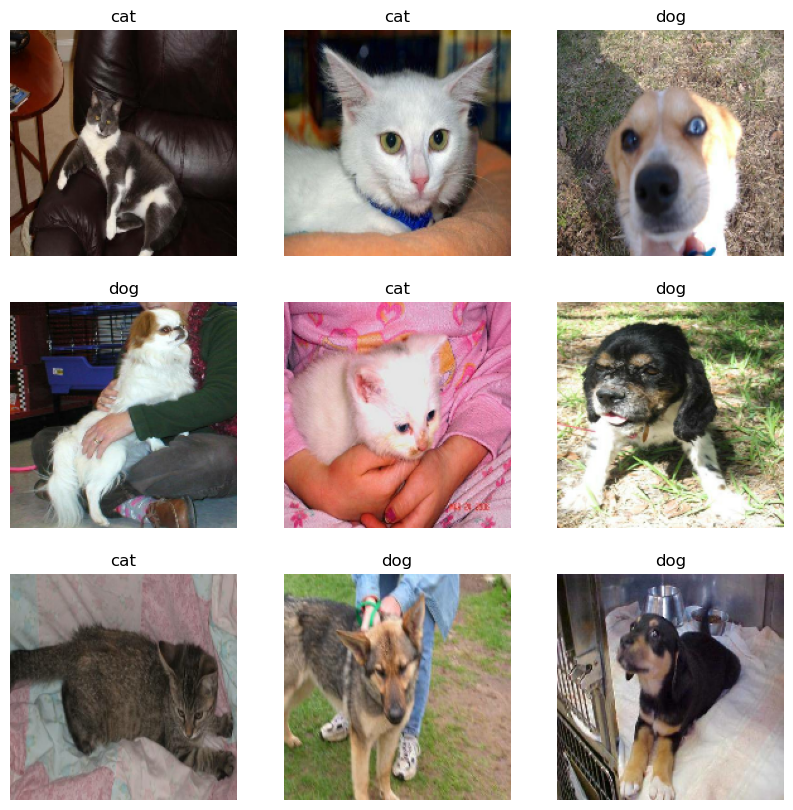

In [25]:
import matplotlib.pyplot as plt

#You can plot the results of the batch (and they're just nice photos)
plt.figure(figsize=(10, 10))
for images, labels in zip(image_batch,labels_batch): #One batch of the dataset!
  for i in range(9):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(image_batch[i].numpy().astype("uint8"))
    plt.title(class_names[labels_batch[i]])
    plt.axis("off")

The Datasets we've created are all we need to get into training our CNNs. We'll move onto the modelling part of this week, but it is worth briefly summarising our steps and highlighting an area for improvement.

What did we do?
* Fixing our folders
    * We started with 1 folder of pictures named {label}.{number}.jpg
    * We converted this into three folders: train, val, test
    * Each of these folders had two subfolders: cat, dog
    * To do that, we created a function that was based on the naming convention of our specific data
* Creating Datasets
    * We created three datasets: train_ds, val_ds, test_ds
    * Each of these used tf.keras.utils.image_dataset_from_directory
    * These objects were created using filepaths for each of our train, val, test folders

What could we improve?
* We'll be loading in data from the disk into our memory, passing it through the forward-backward passes of our CNN. 
* You can optimise this pipeline to make sure data is fetched before it is needed, caching images, etc. 
* These types of optimisations are not particularly hard to implement but aren't our focus. The relevant code is shown but not discussed.

In [26]:
#For more info:
#https://www.tensorflow.org/guide/data_performance
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)
#AUTOTUNE tries to automatically help you with optimisation

## Utility Functions
It is common to define a few functions for any code you want to run more than once. Here, some functions from previous weeks are defined. In practice, you'd normally have a separate .py file that you'd use to load in your functions. To make the code easier to follow, this notebook just defines them here.

Tweaks from earlier weeks:
* We've got a balanced classification problem (50/50 cats/dogs), so we'll use accuracy as our metric instead of AUROC. The function for plotting the training history has been modified to look at 'binary_accuracy' instead of 'auc'.

In [27]:
## Creating a function to make plotting easier:
def plot_training(mdl_hstry):
    """
    Take a trained Keras model's history and produce graphs of training (validation) loss and binary_accuracy
    at the end of each epoch

    @param mdl_hstry - keras.callbacks.History, produced by a keras model
    """

    #Extract model performance across epochs 
    history_dict = mdl_hstry.history
    loss_values = history_dict["loss"]
    val_loss_values = history_dict["val_loss"]
    acc_values = history_dict["binary_accuracy"]
    val_acc_values = history_dict["val_binary_accuracy"]
    epochs = range(1, len(loss_values) + 1)

    # Prepare a 2x1 grid for plotting
    fig, axs = plt.subplots(1, 2, figsize=(10, 5))

    # Plot loss
    axs[0].plot(epochs, loss_values, "bo", label='Train Loss')
    axs[0].plot(epochs, val_loss_values, "b", label='Validation Loss')
    axs[0].set_title('Model Loss')
    axs[0].set_ylabel('Loss')
    axs[0].set_xlabel('Epoch')
    axs[0].legend(loc='right')

    # Plot AUC
    axs[1].plot(epochs, acc_values, "bo", label='Train Acc')
    axs[1].plot(epochs, val_acc_values, "b", label='Validation Acc')
    axs[1].set_title('Model Accuracy')
    axs[1].set_ylabel('Accuracy')
    axs[1].set_xlabel('Epoch')
    axs[1].legend(loc='right')

    #Tidy up and visualise
    plt.tight_layout()
    plt.show()

In [28]:
def print_best_acc(mdl_hstry):
    """
    Take a trained Keras model's history and print the best validation accuracy and associated epoch

    @param mdl_hstry - keras.callbacks.History, produced by a keras model
    """

    val_acc_vals = mdl_hstry.history['val_binary_accuracy']
    max_val = np.max(val_acc_vals)
    max_epoch = np.argmax(val_acc_vals)+1
    
    print(f"Maximum Validation Accuracy = {max_val:.4f} after epoch {max_epoch}")

## Our CNN

Time to set up our first CNN model! Let's start simple and we can always build up. The below code constructs an ANN with:
* A convolutional layer
    * 16 filters
    * Each filter is 5x5
    * Zero-padding = 'same', which retains the height and width dimensions
    * Stride = 1
    * A ReLU activation function
* A maxpooling layers
    * Size = (2,2)
    * Stride = 2 (defaults to the size)
* A fully connected layer
    * One output neuron with a sigmoid activiation function
* Adam optimizer with a learning rate of 3e-4
* 50 epochs
* Batch size equal to the batch size of the Dataset objects (we don't actually specify it here)

We're also going to divide all inputs by 255. Because we don't want to load the entire dataset at once, we'll do this by starting our network with a Rescaling layer.


In [29]:
#Libraries
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Rescaling, Conv2D, MaxPooling2D, Flatten, Dense
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.losses import BinaryCrossentropy
from tensorflow.keras.metrics import BinaryAccuracy
#Again, using tensorflow.keras because you'll see that a lot if you spend time Googling

#tensorflow.keras integrates with TensorFlow, because it is the version of Keras that comes bundled with TensorFlow
#keras on its own allows you to specify different backends, but we keep using tensorflow. 

In [30]:
keras.backend.clear_session() #To avoid objects persisting and messing with some names
#The model
cd_clf = Sequential()
cd_clf.add(Rescaling(1./255, input_shape = (input_dims[0], input_dims[1], 3)))
cd_clf.add(Conv2D(filters = 16, kernel_size = (5,5), activation = 'relu',padding = 'same'))
cd_clf.add(MaxPooling2D(pool_size = (2,2)))
cd_clf.add(Flatten())
cd_clf.add(Dense(1, activation='sigmoid'))
#Compile it:
cd_clf.compile(loss = BinaryCrossentropy(),
               optimizer = Adam(learning_rate=3e-4),
               metrics = BinaryAccuracy())
#Fit it!
cd_clf.fit(
    train_ds,
    validation_data = val_ds,
    epochs = 50,
    verbose = 0 #If you don't want to print results after each epoch
)


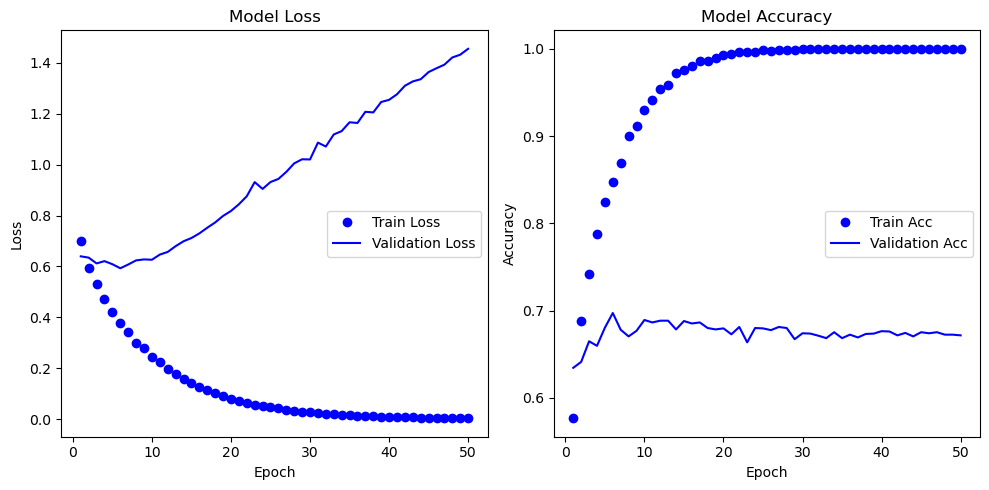

In [31]:
plot_training(cd_clf.history)

In [32]:
print_best_acc(cd_clf.history)

Maximum Validation Accuracy = 0.6972 after epoch 6


#### Interpreting our First Model

We can see that our model's train performance changed substantially at first, but then flatlined. In particular training error very quickly reached zero (100%), after which the network didn't change much (depending on initialisation of weights). Our essentially perfect training performance isn't inherently bad, because we suspect that a good classifier can get close to 100%. It is bad that the validation performance is so much worse though - the perfect training performance demonstrates that the model has memorised the training data rather than learning generalisable relationships between inputs (pictures) and labels (cat or dog). The best validation accuracy is only 69.64%...

We need to fix this, which means we need to reduce our model's variance. You could try regularisation, but let's focus directly on the capacity of our model first. At first glance, it might seem that our model does not have much capacity - it only had two sets of weights (Conv2D and Dense). Unless you delete the convolutional layer, you can't make this network any shallower! In this case, the depth of the network is not perfectly correlated with overfitting potential. If you look at the summary of the model, you'll see that our single Dense layer has 0.13 million weights! The issue is that we've added a fully connected (Dense) layer too soon. When we flatten the 3D output of the convolution->maxpooling layers, we are producing an enormous hidden layer with 0.13 million units. Below, we increase the depth of the network and you can see that the number of weights (trainable parameters) decreases even though we're increasing depth. 

**An aside**: can you explain why the validation accuracy seems to stay flat despite the validation loss increasing?

In [33]:
cd_clf.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 rescaling (Rescaling)       (None, 180, 180, 3)       0         
                                                                 
 conv2d (Conv2D)             (None, 180, 180, 16)      1216      
                                                                 
 max_pooling2d (MaxPooling2D  (None, 90, 90, 16)       0         
 )                                                               
                                                                 
 flatten (Flatten)           (None, 129600)            0         
                                                                 
 dense (Dense)               (None, 1)                 129601    
                                                                 
Total params: 130,817
Trainable params: 130,817
Non-trainable params: 0
__________________________________________________

#### Our Second CNN
The below code creates a similar ANN to before, but now with a second convolutional layer with 32 filters and then another max pooling layer. The usual pattern for CNNs is for each layer to produce a result with greater depth (more filters) but reduced spatial dimensions (height and width).

In [34]:
keras.backend.clear_session() #To avoid objects persisting and messing with some names
#The model
cd_clf = Sequential()
cd_clf.add(Rescaling(1./255, input_shape = (input_dims[0], input_dims[1], 3)))
cd_clf.add(Conv2D(filters = 16, kernel_size = (5,5), activation = 'relu',padding = 'same'))
cd_clf.add(MaxPooling2D(pool_size = (2,2)))
cd_clf.add(Conv2D(filters = 32, kernel_size = (5,5), activation = 'relu',padding = 'same'))
cd_clf.add(MaxPooling2D(pool_size = (2,2)))
cd_clf.add(Flatten())
cd_clf.add(Dense(1, activation='sigmoid'))
#Compile it:
cd_clf.compile(loss = BinaryCrossentropy(),
               optimizer = Adam(learning_rate=3e-4),
               metrics = BinaryAccuracy())
#Fit it!
cd_clf.fit(
    train_ds,
    validation_data = val_ds,
    epochs = 50,
    verbose = 0 #If you don't want to print results after each epoch
)


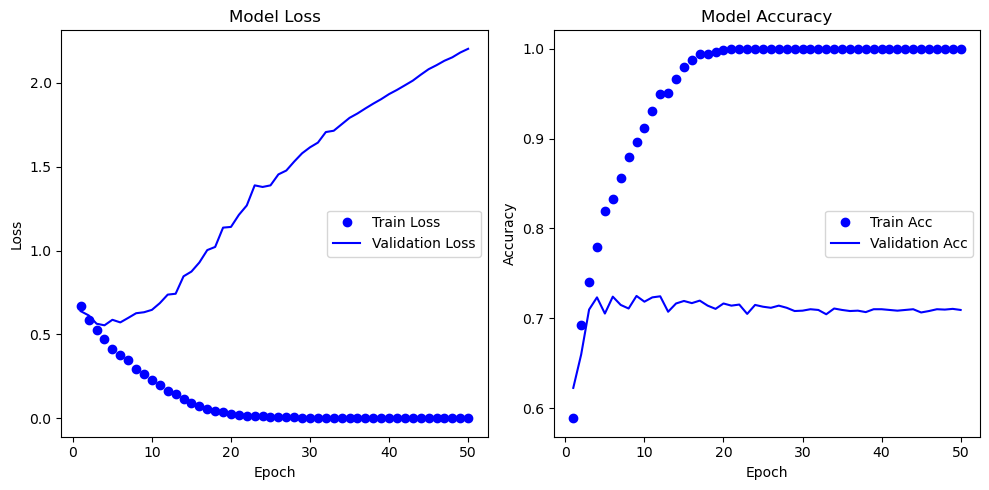

In [35]:
plot_training(cd_clf.history)

In [36]:
print_best_acc(cd_clf.history)

Maximum Validation Accuracy = 0.7248 after epoch 9


In [37]:
cd_clf.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 rescaling (Rescaling)       (None, 180, 180, 3)       0         
                                                                 
 conv2d (Conv2D)             (None, 180, 180, 16)      1216      
                                                                 
 max_pooling2d (MaxPooling2D  (None, 90, 90, 16)       0         
 )                                                               
                                                                 
 conv2d_1 (Conv2D)           (None, 90, 90, 32)        12832     
                                                                 
 max_pooling2d_1 (MaxPooling  (None, 45, 45, 32)       0         
 2D)                                                             
                                                                 
 flatten (Flatten)           (None, 64800)             0

#### Interpreting our Second CNN

We see the same patterns as previously, but with a slight improvement everywhere. In the model summary, you can see we've almost halved the number of parameters (from 0.13 million to 0.078 million). The best validation accuracy when I ran this code has gone from about 69.64% to 71.88%. Perhaps counter-intuitively, the deeper network doesn't appear to have overfit as badly.

Again, we need to improve the model. Again, you could try regularisation. Again, we'll try make the network deeper first. There are two reasons for that. Firstly, we are interested in learning about convolutional layers and how they work in CNNs this week. Regularisation was a focus of another week. Secondly, and more generalisable, we want to understand how our model size affects performance before we optimise other hyperparameters.

#### Our Third CNN
The below code creates a similar ANN to before, but now with a third convolutional layer with 64 filters and then another max pooling layer. The usual pattern for CNNs is for each layer to produce a result with greater depth (more filters) but reduced spatial dimensions (height and width).

In [38]:
keras.backend.clear_session() #To avoid objects persisting and messing with some names
#The model
cd_clf = Sequential()
cd_clf.add(Rescaling(1./255, input_shape = (input_dims[0], input_dims[1], 3)))
cd_clf.add(Conv2D(filters = 16, kernel_size = (5,5), activation = 'relu',padding = 'same'))
cd_clf.add(MaxPooling2D(pool_size = (2,2)))
cd_clf.add(Conv2D(filters = 32, kernel_size = (5,5), activation = 'relu',padding = 'same'))
cd_clf.add(MaxPooling2D(pool_size = (2,2)))
cd_clf.add(Conv2D(filters = 64, kernel_size = (5,5), activation = 'relu',padding = 'same'))
cd_clf.add(MaxPooling2D(pool_size = (2,2)))
cd_clf.add(Flatten())
cd_clf.add(Dense(1, activation='sigmoid'))
#Compile it:
cd_clf.compile(loss = BinaryCrossentropy(),
               optimizer = Adam(learning_rate=3e-4),
               metrics = BinaryAccuracy())
#Fit it!
cd_clf.fit(
    train_ds,
    validation_data = val_ds,
    epochs = 50,
    verbose = 0 #If you don't want to print results after each epoch
)


Epoch 1/50
157/157 [==============================] - 4s 22ms/step - loss: 0.6840 - binary_accuracy: 0.5548 - val_loss: 0.6616 - val_binary_accuracy: 0.5932
Epoch 2/50
157/157 [==============================] - 3s 21ms/step - loss: 0.6159 - binary_accuracy: 0.6716 - val_loss: 0.6150 - val_binary_accuracy: 0.6604
Epoch 3/50
157/157 [==============================] - 3s 21ms/step - loss: 0.5602 - binary_accuracy: 0.7124 - val_loss: 0.5769 - val_binary_accuracy: 0.7072
Epoch 4/50
157/157 [==============================] - 3s 21ms/step - loss: 0.5080 - binary_accuracy: 0.7536 - val_loss: 0.5484 - val_binary_accuracy: 0.7312
Epoch 5/50
157/157 [==============================] - 3s 21ms/step - loss: 0.4625 - binary_accuracy: 0.7836 - val_loss: 0.5277 - val_binary_accuracy: 0.7404
Epoch 6/50
157/157 [==============================] - 3s 21ms/step - loss: 0.4140 - binary_accuracy: 0.8146 - val_loss: 0.5100 - val_binary_accuracy: 0.7480
Epoch 7/50
157/157 [==============================] - 3s 2

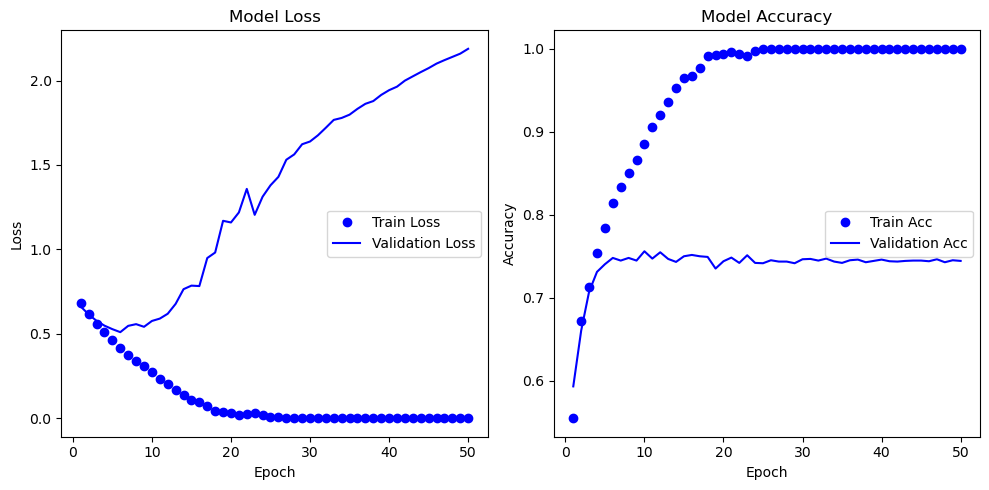

In [39]:
plot_training(cd_clf.history)

In [40]:
print_best_acc(cd_clf.history)

Maximum Validation Accuracy = 0.7560 after epoch 10


In [41]:
cd_clf.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 rescaling (Rescaling)       (None, 180, 180, 3)       0         
                                                                 
 conv2d (Conv2D)             (None, 180, 180, 16)      1216      
                                                                 
 max_pooling2d (MaxPooling2D  (None, 90, 90, 16)       0         
 )                                                               
                                                                 
 conv2d_1 (Conv2D)           (None, 90, 90, 32)        12832     
                                                                 
 max_pooling2d_1 (MaxPooling  (None, 45, 45, 32)       0         
 2D)                                                             
                                                                 
 conv2d_2 (Conv2D)           (None, 45, 45, 64)        5

#### Interpreting our Third CNN

We have the same patterns - the model's training error quickly reaches zero while validation performance plateaus much earlier. As was the case when going from our first to second CNN, our best validation performance is improved (71.88% to 76.60%), indicating that the network captured more generalisable features before overfitting the training data.

Unlike when going from our first to second CNN, the number of weights has increased (0.096 million). As the final dense layer increases in size, the depth of the network will be more closely linked to your number of parameters because the added parameters from convolutional layers are greater than the reduction in parameters in the final dense layer. When the flattened volume at the end of our network is (relatively) small, we could also include more than one fully connected layer at the end. This is relatively common. 

Final thing - let's do a fourth model before you start trying to improve the model yourself. 

#### Our Fourth CNN
The below code creates a similar ANN to before, but now with a fourth convolutional layer with 128 filters and then another max pooling layer. The usual pattern for CNNs is for each layer to produce a result with greater depth (more filters) but reduced spatial dimensions (height and width).

In [42]:
keras.backend.clear_session() #To avoid objects persisting and messing with some names
#The model
cd_clf = Sequential()
cd_clf.add(Rescaling(1./255, input_shape = (input_dims[0], input_dims[1], 3)))
cd_clf.add(Conv2D(filters = 16, kernel_size = (5,5), activation = 'relu',padding = 'same'))
cd_clf.add(MaxPooling2D(pool_size = (2,2)))
cd_clf.add(Conv2D(filters = 32, kernel_size = (5,5), activation = 'relu',padding = 'same'))
cd_clf.add(MaxPooling2D(pool_size = (2,2)))
cd_clf.add(Conv2D(filters = 64, kernel_size = (5,5), activation = 'relu',padding = 'same'))
cd_clf.add(MaxPooling2D(pool_size = (2,2)))
cd_clf.add(Conv2D(filters = 128, kernel_size = (5,5), activation = 'relu',padding = 'same'))
cd_clf.add(MaxPooling2D(pool_size = (2,2)))
cd_clf.add(Flatten())
cd_clf.add(Dense(1, activation='sigmoid'))
#Compile it:
cd_clf.compile(loss = BinaryCrossentropy(),
               optimizer = Adam(learning_rate=3e-4),
               metrics = BinaryAccuracy())
#Fit it!
cd_clf.fit(
    train_ds,
    validation_data = val_ds,
    epochs = 50,
    verbose = 1 #If you don't want to print results after each epoch
)


Epoch 1/50
157/157 [==============================] - 4s 24ms/step - loss: 0.6813 - binary_accuracy: 0.5578 - val_loss: 0.6462 - val_binary_accuracy: 0.6224
Epoch 2/50
157/157 [==============================] - 3s 22ms/step - loss: 0.6076 - binary_accuracy: 0.6824 - val_loss: 0.5957 - val_binary_accuracy: 0.6780
Epoch 3/50
157/157 [==============================] - 3s 22ms/step - loss: 0.5348 - binary_accuracy: 0.7314 - val_loss: 0.5636 - val_binary_accuracy: 0.7096
Epoch 4/50
157/157 [==============================] - 4s 22ms/step - loss: 0.4801 - binary_accuracy: 0.7758 - val_loss: 0.5161 - val_binary_accuracy: 0.7464
Epoch 5/50
157/157 [==============================] - 3s 22ms/step - loss: 0.4280 - binary_accuracy: 0.8088 - val_loss: 0.5519 - val_binary_accuracy: 0.7408
Epoch 6/50
157/157 [==============================] - 3s 22ms/step - loss: 0.3803 - binary_accuracy: 0.8318 - val_loss: 0.4891 - val_binary_accuracy: 0.7672
Epoch 7/50
157/157 [==============================] - 3s 2

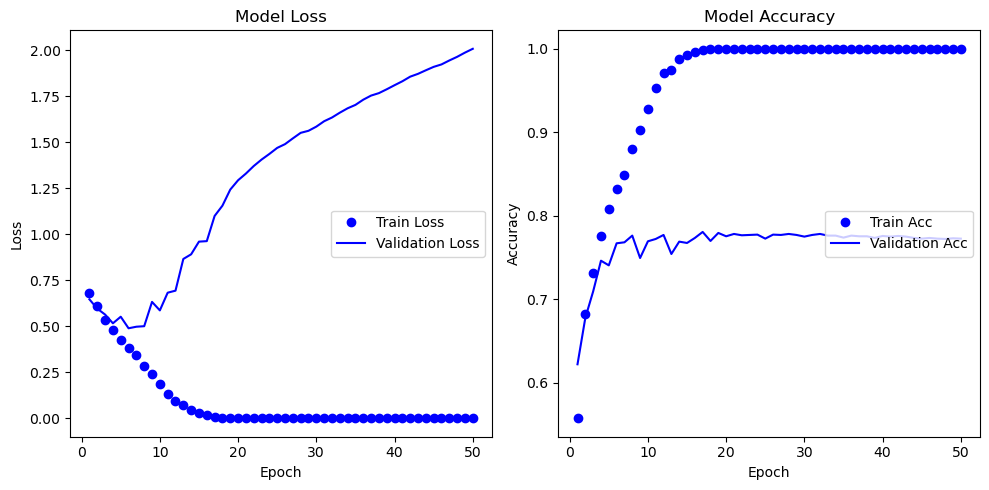

In [43]:
plot_training(cd_clf.history)

In [44]:
print_best_acc(cd_clf.history)

Maximum Validation Accuracy = 0.7808 after epoch 17


In [45]:
cd_clf.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 rescaling (Rescaling)       (None, 180, 180, 3)       0         
                                                                 
 conv2d (Conv2D)             (None, 180, 180, 16)      1216      
                                                                 
 max_pooling2d (MaxPooling2D  (None, 90, 90, 16)       0         
 )                                                               
                                                                 
 conv2d_1 (Conv2D)           (None, 90, 90, 32)        12832     
                                                                 
 max_pooling2d_1 (MaxPooling  (None, 45, 45, 32)       0         
 2D)                                                             
                                                                 
 conv2d_2 (Conv2D)           (None, 45, 45, 64)        5

#### Interpreting our Fourth Model

We again see the same pattern of results - same shapes in our plots, better validation performance, and now a bigger increase in parameter count. 

## Your turn

This is a nice point to pass the problem onto you. That doesn't mean close this document and do other things! I strongly encourage you to start experimenting to understand the effect of different hyperparameters. We still haven't established what a 'good' model is on this dataset - how hard is it to beat 78% accuracy?

A few questions to guide your exploration of the problem:
* If you add another pair of convolution and pooling layers, your parameter count is going to increase again. Do you think this increase in parameters will start to cause validation accuracy to decrease? Try it!
* We used a 5x5 filter - what if you used 3x3 instead?
* What if you removed the zero-padding by specifying `padding='valid'` and also removed the maxpooling?
* For a relatively deep model (e.g., CNN 4), compare the efficacy of weight regularisation vs dropout regularisation.
* Is the rescaling necessary? The pixels should all have ranges between 0 and 255. Does the equivalent ranges mean scaling isn't needed?

It is a bit of a spoiler, but it is rare that dropout gets used in CNNs. Recent research has started investigating modifications of dropout for CNNs. For example: [DropBlock](https://arxiv.org/abs/1810.12890). The dropoout method reduces correlation of activations in a fully connected network, but images have strong spatial correlation even when you dropout a random subset of activations. 

In [48]:
## When you are done, save your final model
# You may wish to use this model for some of next week's examples

#In the below code, make sure to update the file path to match your computer and to define your model.  

from keras.callbacks import ModelCheckpoint
checkpointer = ModelCheckpoint(filepath = core_path+"CatDogCNN.keras", #Where to save your model
                               monitor = "val_binary_accuracy", #The metric monitored to determine whether to save the current model
                               save_best_only= True) #Overwrite earlier, poorer models
#<design and compile your network here>
cd_clf.fit(
    train_ds,
    validation_data = val_ds,
    epochs = 50,
    verbose = 0, #If you don't want to print results after each epoch
    callbacks = [checkpointer]
)